# 二乗回路と平方根回路

**二乗回路**は、入力の 2 乗に比例した電圧を出す回路です。アナログの掛け算器(乗算器)の 2 つの入力に同じ信号を入れて作ります。電圧の 2 乗は電力に比例するので、電力や実効値(7-3)を求めるところで使います。正弦波を 2 乗すると、周波数が 2 倍になります(周波数逓倍)。

**平方根回路**はその逆です。オリフィスやピトー管で流れを測ると、差圧は流速の 2 乗に比例するので、差圧センサーの出力の平方根をとると流速(流量)になります。

この回では、正弦波を 2 乗して周波数が 2 倍になること、二乗回路の入出力特性、平方根回路の入出力特性、の 3 つを見ます。

## 回路

![二乗回路](02_square/circuit_squarer.svg) ![平方根回路](02_square/circuit_rooter.svg)

**二乗回路**(左):アナログの乗算器(AD633 など)は、2 つの入力 X、Y から $XY/10\,\mathrm{V}$ を出します。X と Y に同じ入力をつなぐと、$V_\mathrm{in}^2/10\,\mathrm{V}$ になります。10 V は「単位の電圧(unit)」で、入力が unit のとき出力も unit になります。

**平方根回路**(右):乗算器をオペアンプの帰還に入れます。オペアンプは − 入力が 0 V になるように出力を動かすので、乗算器の出力($V_\mathrm{out}^2$/unit)が入力と釣り合います。つまり $V_\mathrm{out}^2/\text{unit} = V_\mathrm{in}$ となって、$V_\mathrm{out} = \sqrt{\text{unit} \times V_\mathrm{in}}$ です(実際の回路では符号に合わせて反転を入れ、負の入力でオペアンプが張りつかないようにダイオードを入れます)。

## 原理

Mimic の二乗回路と平方根回路は、入力の Vref からのずれ $d = V_\mathrm{in} - V_\mathrm{ref}$ を計算に使い、**0 V からの大きさ**を出します。

$$\text{二乗:}\quad V_\mathrm{out} = \frac{d^2}{\text{unit}} \qquad\qquad \text{平方根:}\quad V_\mathrm{out} = \sqrt{d \times \text{unit}}\quad(d < 0 \text{ では } 0)$$

unit を 0 にすると VDD/4 = 1.25 V を使います(入力 Vref ± 2.5 V で出力 5 V)。同じ unit の二乗回路と平方根回路をつなぐと、$|d|$ に戻ります。

**周波数が 2 倍になる**:振幅 A の正弦波を 2 乗すると

$$\frac{(A \sin\omega t)^2}{\text{unit}} = \frac{A^2}{2\,\text{unit}} - \frac{A^2}{2\,\text{unit}}\cos 2\omega t$$

で、平均 $A^2/(2\,\text{unit})$ のまわりを、**2 倍の周波数**で振れる波になります。正の山も負の谷も、2 乗すると同じ正の山になるからです。平均は $A^2$ に比例するので、振幅が 2 倍なら 4 倍です(電力と同じ)。

**出力の下の端**:Mimic の出力は 0.1 V より下を出せないので、0 V からの出力は下の 0.1 V が切れます。この回では `output_offset(0.5)` で出力を 0.5 V 持ち上げて、下まで見えるようにします(式の値 + 0.5 V が出ます)。

![二乗と平方根(模式図)](02_square/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.squarer(unit)` | `mimic.setSquarer(unit)` | 乗算器の単位の電圧 unit(V)。0 で VDD/4 |
| `lab.mimic.square_rooter(unit)` | `mimic.setSquareRooter(unit)` | 同じ |
| `lab.mimic.output_offset(volts)` | `mimic.setOutputOffset(volts)` | 出力に足す電圧(すべてのモードに効く。最後に 0 に戻す) |

- 下の準備のセルの `dc_sweep` と `scope_xy` は 7-1 と同じです。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from mimiclab import MimicLab, measure

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.5, mimic=20261125)

In [2]:
def dc_sweep(inputs, label="output"):
    # Puts each DC voltage on the input and returns the measured (input, output) in V.
    # The plot shows the waveforms at each input while measuring (the last one stays).
    fig, ax = plt.subplots(figsize=(8, 3))
    handle = display(fig, display_id=True)
    vin, vout = [], []
    for v in inputs:
        lab.fg.dc(v)
        time.sleep(0.05)
        t, ch1, ch2 = lab.scope.capture(400)   # 20 ms
        vin.append(ch1.mean())
        vout.append(ch2.mean())
        ax.clear()
        ax.plot(t * 1e3, ch1, label="CH1: input")
        ax.plot(t * 1e3, ch2, label=f"CH2: {label}")
        ax.set_ylim(-0.2, 5.2)
        ax.set_title(f"input {vin[-1]:.3f} V: output {vout[-1]:.3f} V")
        ax.set_xlabel("Time [ms]")
        ax.set_ylabel("Voltage [V]")
        ax.grid(True)
        ax.legend(loc="upper right")
        fig.tight_layout()
        if handle is not None:   # None outside a notebook
            handle.update(fig)
    plt.close(fig)   # the display keeps the last picture
    return np.array(vin), np.array(vout)


def scope_xy(t, ch1, ch2, label, theory=None):
    # Left: the waveforms; right: the output against the input (with the theory curve)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".", ms=2, color="C2", label="measured")
    if theory is not None:
        x = np.linspace(ch1.min(), ch1.max(), 200)
        ax2.plot(x, theory(x), "k--", lw=1, label="theory")
        ax2.legend(loc="upper left", fontsize=8)
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()

## 実験 1:正弦波を 2 乗する

100 Hz、振幅 1 V の正弦波を二乗回路(unit = 1.25 V)に入れ、出力を 0.5 V 持ち上げて見ます。出力は 0.5〜1.3 V を 200 Hz で振れ、平均は 0.5 + 1/(2 × 1.25) = 0.9 V になるはずです。

input 100.0 Hz, output 200.0 Hz
output 0.499 - 1.306 V, mean 0.901 V (theory 0.5 - 1.3 V, mean 0.9 V)


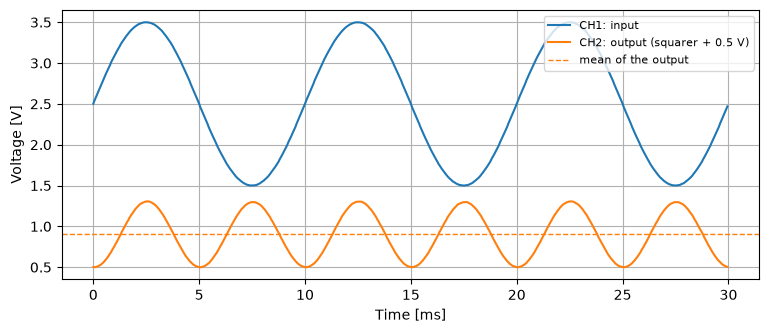

In [3]:
OFFSET = 0.5   # [V] lifts the output, to see the bottom
lab.fg.sine(100, 1.0)
lab.mimic.output_offset(OFFSET)
lab.mimic.squarer()                     # unit 0: VDD / 4 = 1.25 V
time.sleep(0.05)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
f1, f2 = measure(t, ch1)[1], measure(t, ch2)[1]
print(f"input {f1:.1f} Hz, output {f2:.1f} Hz")
print(f"output {ch2.min():.3f} - {ch2.max():.3f} V, mean {ch2.mean():.3f} V "
      f"(theory {OFFSET:.1f} - {OFFSET + 0.8:.1f} V, mean {OFFSET + 0.4:.1f} V)")
n = t < 0.03
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t[n] * 1e3, ch1[n], label="CH1: input")
ax.plot(t[n] * 1e3, ch2[n], label="CH2: output (squarer + 0.5 V)")
ax.axhline(ch2.mean(), color="C1", ls="--", lw=1, label="mean of the output")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend(loc="upper right", fontsize=8)
plt.show()

出力の山は、入力の山と谷の両方のところに来るので、山の数が 2 倍(200 Hz)になっています。入力が Vref を横切るところで、出力はいちばん下(0.5 V、式の値で 0 V)まで下がります。

## 実験 2:二乗回路の入出力特性

20 Hz、振幅 2 V(0.5〜4.5 V)の三角波を入れ、入力を横軸、出力を縦軸にして描きます。Vref(2.5 V)を底にした放物線になるはずです。

output 0.498 - 3.733 V (theory 0.5 - 3.7 V)


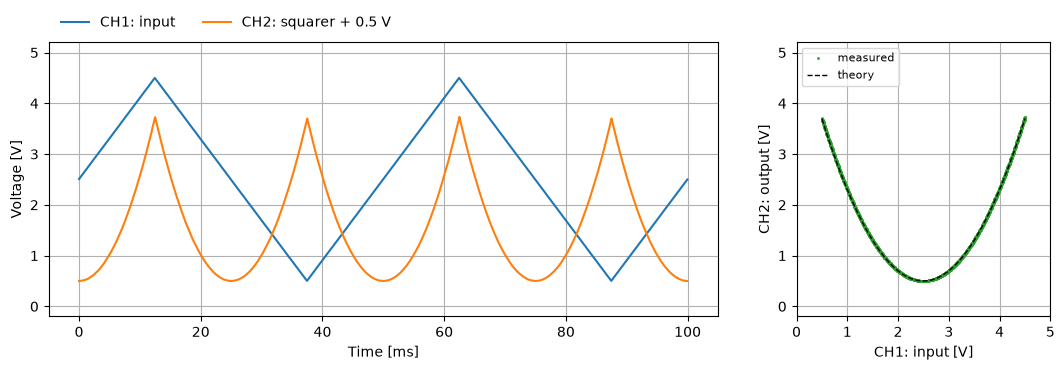

In [4]:
lab.fg.triangle(20, 2.0)
lab.mimic.squarer()
time.sleep(0.05)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output {ch2.min():.3f} - {ch2.max():.3f} V (theory {OFFSET:.1f} - {OFFSET + 2.0**2 / 1.25:.1f} V)")
scope_xy(t, ch1, ch2, "squarer + 0.5 V", theory=lambda x: OFFSET + (x - 2.5) ** 2 / 1.25)

入力が Vref から 1 V 離れると出力は 0.8 V、2 V 離れると 3.2 V と、離れるほど急に大きくなります。Vref の上でも下でも同じ値になるので、出力からは入力の向き(Vref より上か下か)がわかりません。

## 実験 3:平方根回路の入出力特性

平方根回路(unit = 1.25 V)に、Vref − 0.5 V〜Vref + 2.3 V の直流を入れて出力を測ります。出力から持ち上げた 0.5 V を引くと、$\sqrt{d \times 1.25}$ になり、Vref より下では 0 になるはずです。

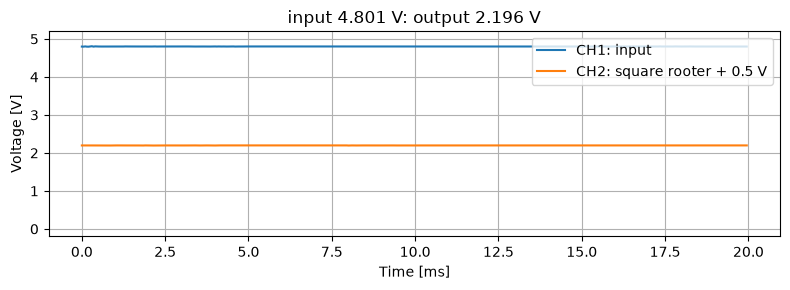

input - Vref -0.500 V: output - offset 0.000 V (theory 0.000 V)
input - Vref +0.001 V: output - offset 0.060 V (theory 0.034 V)
input - Vref +0.051 V: output - offset 0.256 V (theory 0.252 V)
input - Vref +0.101 V: output - offset 0.358 V (theory 0.355 V)
input - Vref +0.201 V: output - offset 0.503 V (theory 0.501 V)
input - Vref +0.501 V: output - offset 0.792 V (theory 0.792 V)
input - Vref +1.000 V: output - offset 1.118 V (theory 1.118 V)
input - Vref +1.501 V: output - offset 1.371 V (theory 1.370 V)
input - Vref +2.001 V: output - offset 1.582 V (theory 1.581 V)
input - Vref +2.301 V: output - offset 1.696 V (theory 1.696 V)


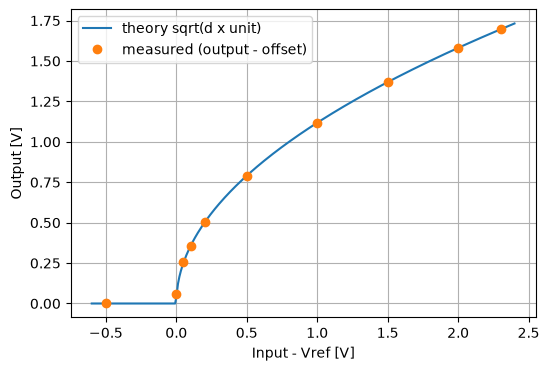

In [5]:
lab.mimic.square_rooter()
d = np.array([-0.5, 0.0, 0.05, 0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 2.3])   # input - Vref [V]
vin, vout = dc_sweep(2.5 + d, "square rooter + 0.5 V")
for a, b in zip(vin, vout):
    print(f"input - Vref {a - 2.5:+.3f} V: output - offset {b - OFFSET:.3f} V "
          f"(theory {np.sqrt(max(a - 2.5, 0) * 1.25):.3f} V)")

fig, ax = plt.subplots(figsize=(6, 4))
x = np.linspace(-0.6, 2.4, 300)
ax.plot(x, np.sqrt(np.maximum(x, 0) * 1.25), "-", label="theory sqrt(d x unit)")
ax.plot(vin - 2.5, vout - OFFSET, "o", label="measured (output - offset)")
ax.set_xlabel("Input - Vref [V]")
ax.set_ylabel("Output [V]")
ax.grid(True)
ax.legend()
plt.show()

出力は、入力の小さいところで急に立ち上がり、大きいところではゆっくり増えます。入力が 4 倍(0.5 V → 2.0 V)になると、出力は 2 倍(0.79 V → 1.58 V)です。いっぽう、Vref のすぐ上では曲線の傾きがとても急なので、入力の数 mV の雑音やずれでも出力が大きく動きます(入力 0 V のところが 0 ではなく、数十 mV になることがあります)。二乗とは逆に、小さい入力を大きく、大きい入力を小さく表すので、平方根も一種の「圧縮」です。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 振幅と平均(電力)
<details><summary>ヒント</summary>

はじめは `AMP = 1.0` です。`AMP` を 0.5 → 1.5 → 2.0 と変えてみましょう。出力の平均(持ち上げた 0.5 V を除く)は 0.1、0.9、1.6 V と、振幅の 2 乗に比例します(振幅 0.5 → 1.0 → 2.0 で 1 : 4 : 16)。抵抗にかかる電圧が 2 倍になると、電力が 4 倍になるのと同じです。周波数は、どの振幅でも 200 Hz です。

</details>

mean - offset 0.401 V (theory A^2 / (2 unit) = 0.400 V), output 200.0 Hz


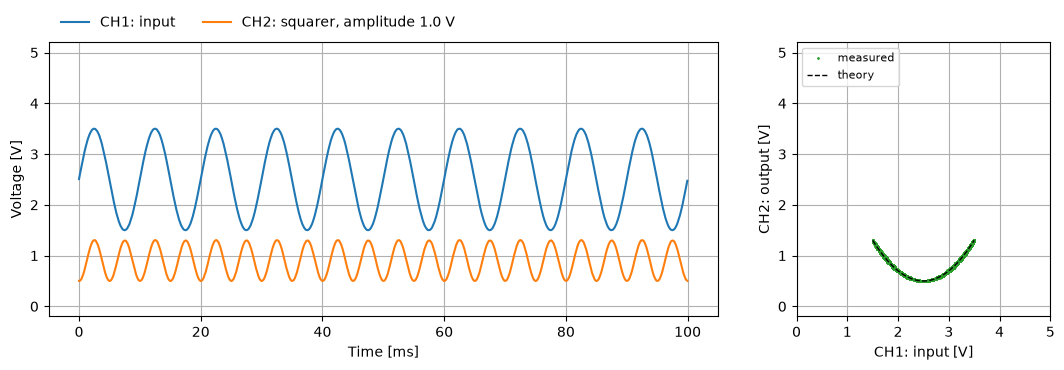

In [6]:
AMP = 1.0   # [V]

lab.fg.sine(100, AMP)
lab.mimic.squarer()
time.sleep(0.05)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"mean - offset {ch2.mean() - OFFSET:.3f} V (theory A^2 / (2 unit) = {AMP**2 / 2.5:.3f} V), "
      f"output {measure(t, ch2)[1]:.1f} Hz")
scope_xy(t, ch1, ch2, f"squarer, amplitude {AMP} V", theory=lambda x: OFFSET + (x - 2.5) ** 2 / 1.25)

### 2. 入力の中心をずらす
<details><summary>ヒント</summary>

はじめは `CENTER = 2.5` です(Vref と同じ)。`CENTER` を 2.7 → 3.0 → 3.5 と変えてみましょう。正弦波の中心が Vref からずれると、山と谷で 2 乗した高さが違うので、出力の山が 1 つおきに高く、低くなります。$(D + A\sin\omega t)^2 = D^2 + A^2/2 + 2DA\sin\omega t - (A^2/2)\cos 2\omega t$ で、入力と同じ周波数の成分 $2DA\sin\omega t$ が出てくるからです。2.7 V でもう、低いほうの山が平均のまわりのしきい(`measure` が使う)に届かなくなり、測った周波数は 200 Hz から 100 Hz に変わります。周波数を 2 倍にしたいときは、入力の中心を Vref にそろえることが大事です。

</details>

output 200.0 Hz, 0.499 - 1.154 V


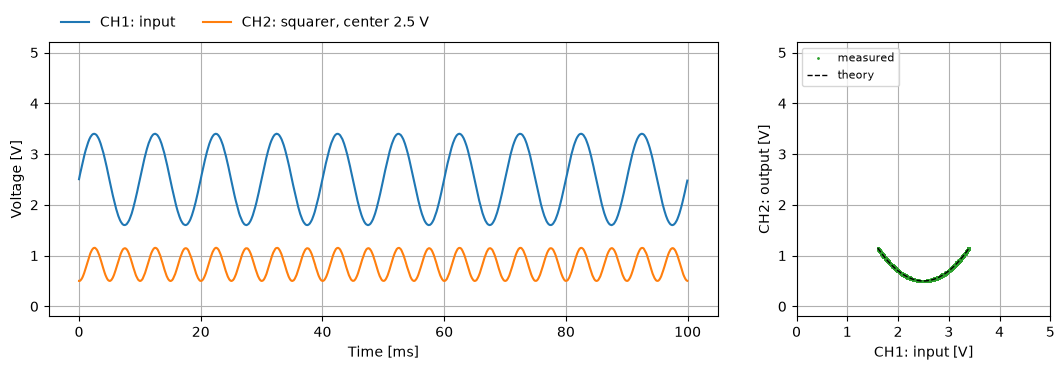

In [7]:
CENTER = 2.5   # [V] the center of the input sine

lab.fg.sine(100, 0.9, CENTER)
lab.mimic.squarer()
time.sleep(0.05)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output {measure(t, ch2)[1]:.1f} Hz, {ch2.min():.3f} - {ch2.max():.3f} V")
scope_xy(t, ch1, ch2, f"squarer, center {CENTER} V", theory=lambda x: OFFSET + (x - 2.5) ** 2 / 1.25)

### 3. 単位の電圧(unit)
<details><summary>ヒント</summary>

はじめは `UNIT = 1.25` です。`UNIT` を 2.5 → 0.625 と変えてみましょう。二乗回路の出力は unit に反比例するので、2.5 V では半分(山 0.4 V)、0.625 V では 2 倍(山 1.6 V)になります。乗算器の 10 V のように、unit は「どの大きさの入力で出力が入力と同じになるか」を決めます(入力 − Vref = unit のとき、出力 = unit)。

</details>

peak - offset 0.806 V (theory 1 / unit = 0.800 V)


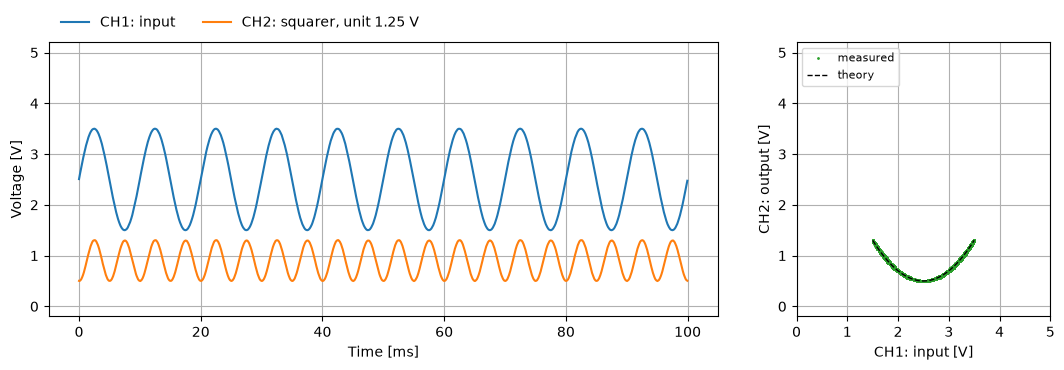

In [8]:
UNIT = 1.25   # [V]

lab.fg.sine(100, 1.0)
lab.mimic.squarer(UNIT)
time.sleep(0.05)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"peak - offset {ch2.max() - OFFSET:.3f} V (theory 1 / unit = {1 / UNIT:.3f} V)")
scope_xy(t, ch1, ch2, f"squarer, unit {UNIT} V", theory=lambda x: OFFSET + (x - 2.5) ** 2 / UNIT)

## まとめ

- 二乗回路は、乗算器の 2 つの入力に同じ信号を入れて作る。出力は $d^2$/unit。正弦波は 2 倍の周波数になり、平均は振幅の 2 乗(電力)に比例する。
- 平方根回路は、乗算器をオペアンプの帰還に入れて作る。出力は $\sqrt{d \times \text{unit}}$。差圧から流量を求めるのに使う。
- Mimic の二乗回路と平方根回路の出力は 0 V からの大きさ。下の端を見るには `output_offset` で持ち上げる。
- Mimic では `squarer(unit)`、`square_rooter(unit)`。二乗 → 平均 → 平方根で実効値になる(次の 7-3)。

最後に出力のオフセットを 0 に戻し、Mimic を素通し(バイパス)にして、接続を閉じます。

In [9]:
lab.mimic.output_offset(0)
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()